# Facebook Prophet — Decomposable Additive Time Series Model
**Model**: `Prophet`  
**Milestone**: M6a — Linear & Statistical Models  
**Evaluated Problems**:
- **D1**: Karnataka Grid Demand (1-hour ahead)
- **D24**: Karnataka Grid Demand (24-hours ahead)
- **S1**: Pavagada Solar Generation (1-hour ahead)
- **S24**: Pavagada Solar Generation (24-hours ahead)

### Purpose & Theoretical Formulation
Prophet decomposes time series into trend $g(t)$, seasonality $s(t)$ (hourly, daily, weekly, yearly Fourier terms), and holiday effects $h(t)$, plus user-provided exogenous regressors (temperature, irradiance):
$$y(t) = g(t) + s(t) + h(t) + \sum \beta_i x_{i,t} + \epsilon_t$$


In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

project_root = Path.cwd().parent.parent if Path.cwd().name == "linear_statistical" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
import src.models_stat as ms

print("Project root successfully linked:", project_root)


Project root successfully linked: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT


## 1. Train Prophet on Problems

In [2]:
problems = ["D1", "D24", "S1", "S24"]
results = []

for pid in problems:
    res = ms.train_and_eval_prophet(problem_id=pid, train_window=8760)
    ms.plot_model_diagnostics(res)
    results.append(res)


LOADING PROCESSED DATASET FOR PROBLEM: D1
Target: demand_mw | Horizon: 1h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_D1.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_D1.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_D1.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_D1.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_D1.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_D1.parquet (44 features, strictly quarantined)

Training PROPHET on D1 (2 exogenous regressors)...


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


10:56:42 - cmdstanpy - INFO - Chain [1] start processing


10:56:43 - cmdstanpy - INFO - Chain [1] done processing


Saved Prophet artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\prophet_D1.joblib


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.


... (10 outputs left out)

LOADING PROCESSED DATASET FOR PROBLEM: S24
Target: solar_power_mw | Horizon: 24h
Using Scaled Features: False
• Training Features Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_train_S24.parquet
• Training Target Path:     C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_train_S24.parquet
• Validation Features Path: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_val_S24.parquet
• Validation Target Path:   C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\y_val_S24.parquet
• Test Features Path:       C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\data\processed\X_test_S24.parquet (QUARANTINED - NOT TOUCHED)
Loaded Train: 33,480 rows (2021-03-08 00:00:00 to 2024-12-31 23:00:00)
Loaded Val:   8,760 rows (2025-01-01 00:00:00 to 2025-12-31 23:00:00)
Test Available: X_test_S24.parquet (41 features, strictly quarantined)

Training PROPHET on S24 (3 exogenous regressors)...


10:56:53 - cmdstanpy - INFO - Chain [1] start processing


10:56:54 - cmdstanpy - INFO - Chain [1] done processing


Saved Prophet artifact: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\models\prophet_S24.joblib


## 2. Validation Metrics Table

In [3]:
metrics_df = ms.save_and_record_results(results, "prophet")
display(metrics_df)



Saved validation predictions to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\predictions\prophet_val_predictions.parquet
Saved validation metrics table to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\tables\prophet_val_metrics.csv


,model,problem,target,horizon,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,mbe,skill_vs_persistence,daylight_rmse,daylight_mae,daylight_nmae_pct
0,prophet,D1,demand_mw,1h,1310.98,1208.90,9.6,9.68,10.26,0.6140,-1195.37,-95.68,NaN,NaN,NaN
1,prophet,D24,demand_mw,24h,1310.98,1208.90,9.6,9.68,10.26,0.6140,-1195.37,-69.97,NaN,NaN,NaN
2,prophet,S1,solar_power_mw,1h,50.91,18.36,0.9,NaN,14.28,0.9922,-5.62,75.88,71.73,36.44,1.78
3,prophet,S24,solar_power_mw,24h,50.91,18.36,0.9,NaN,14.28,0.9922,-5.62,76.01,71.73,36.44,1.78


## 3. Diagnostic Visualizations


DIAGNOSTIC PLOTS FOR PROBLEM D1


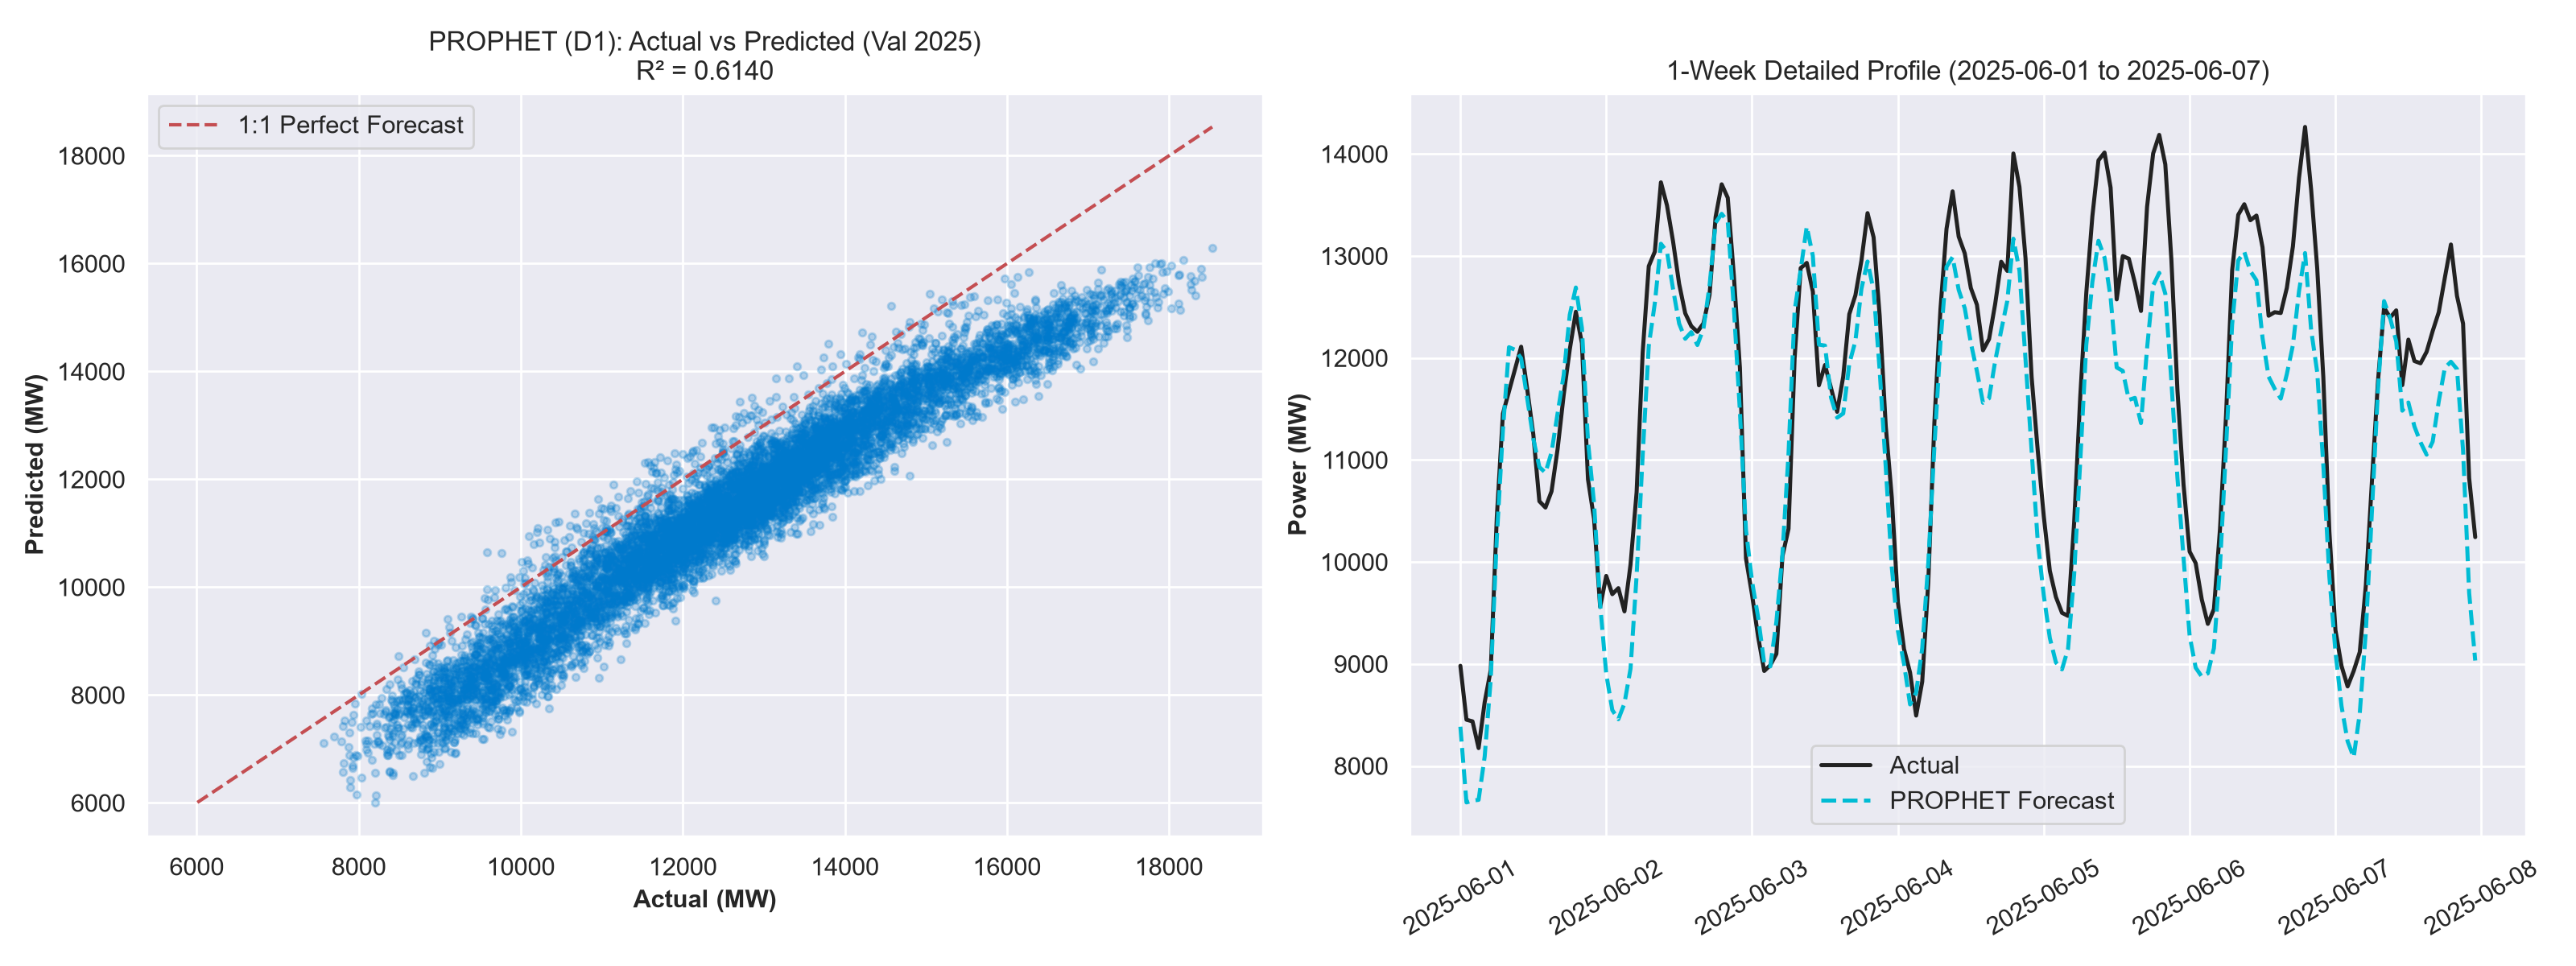

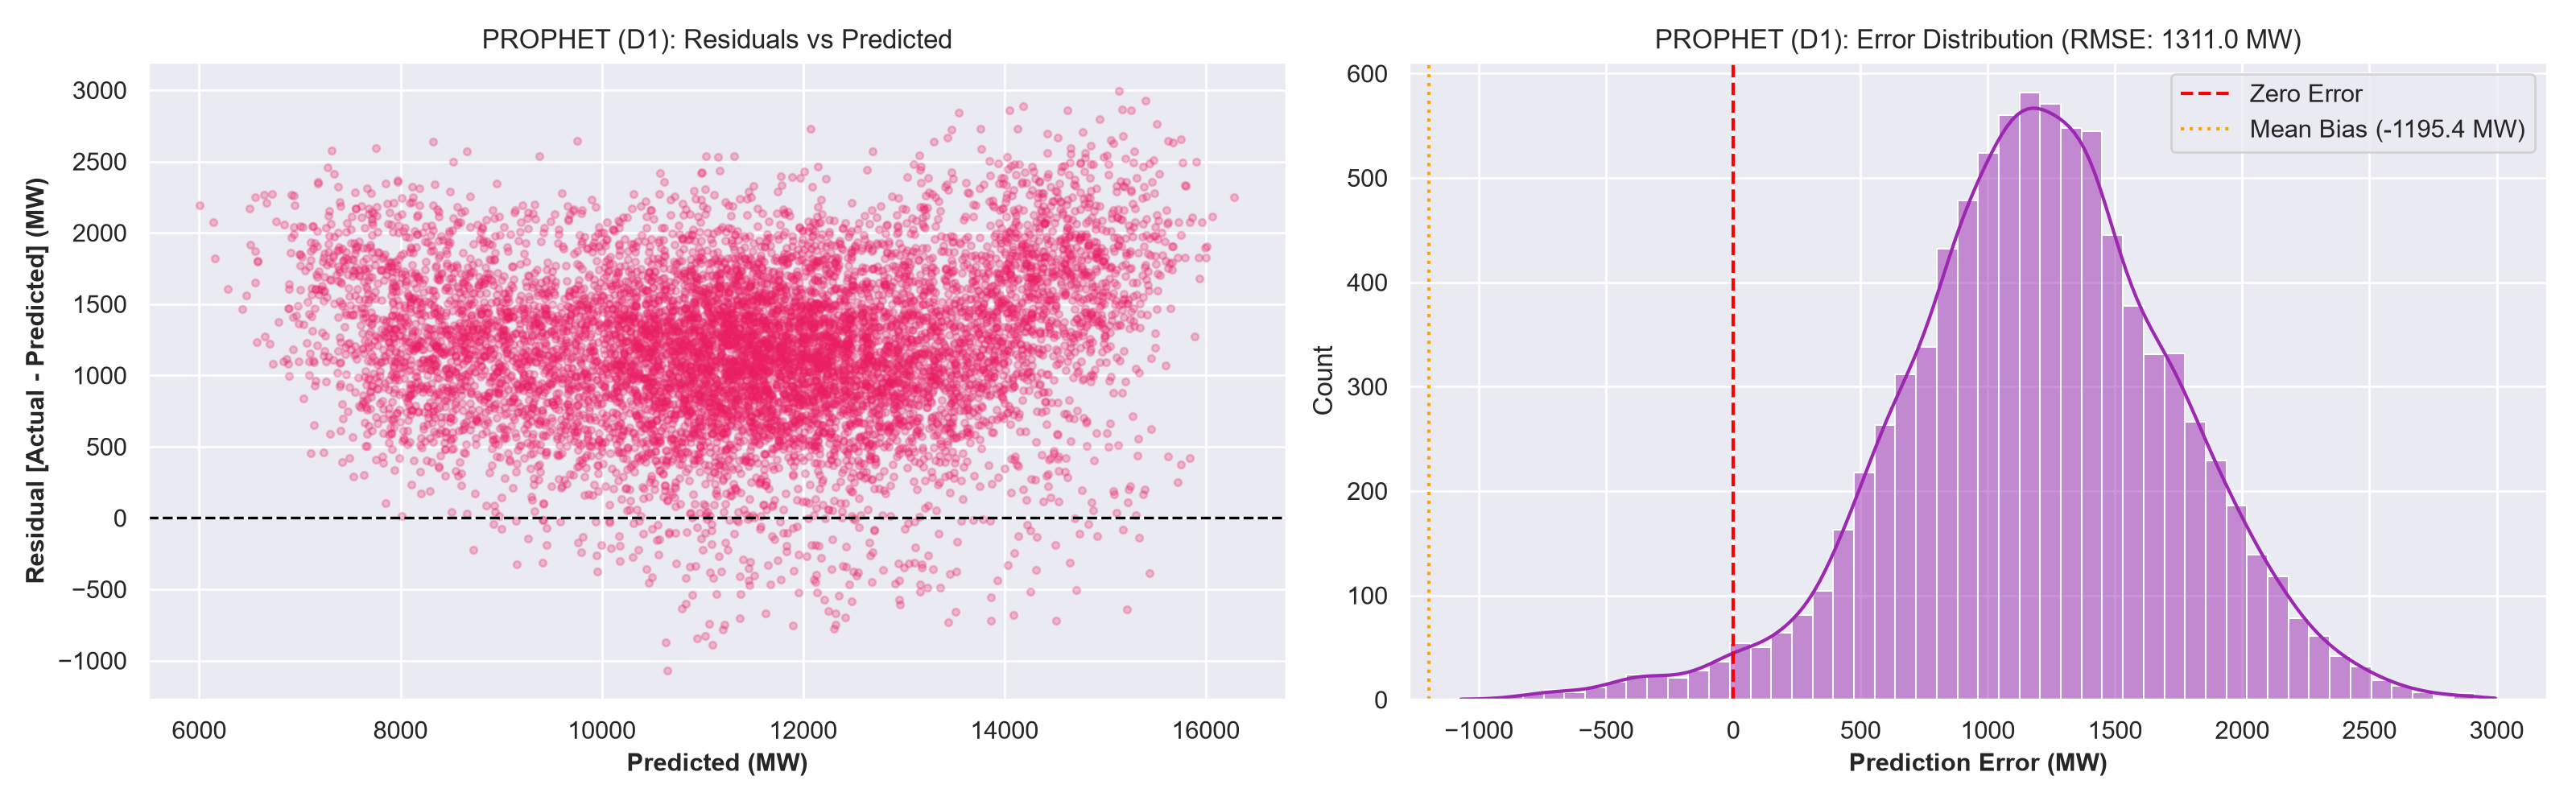


DIAGNOSTIC PLOTS FOR PROBLEM D24


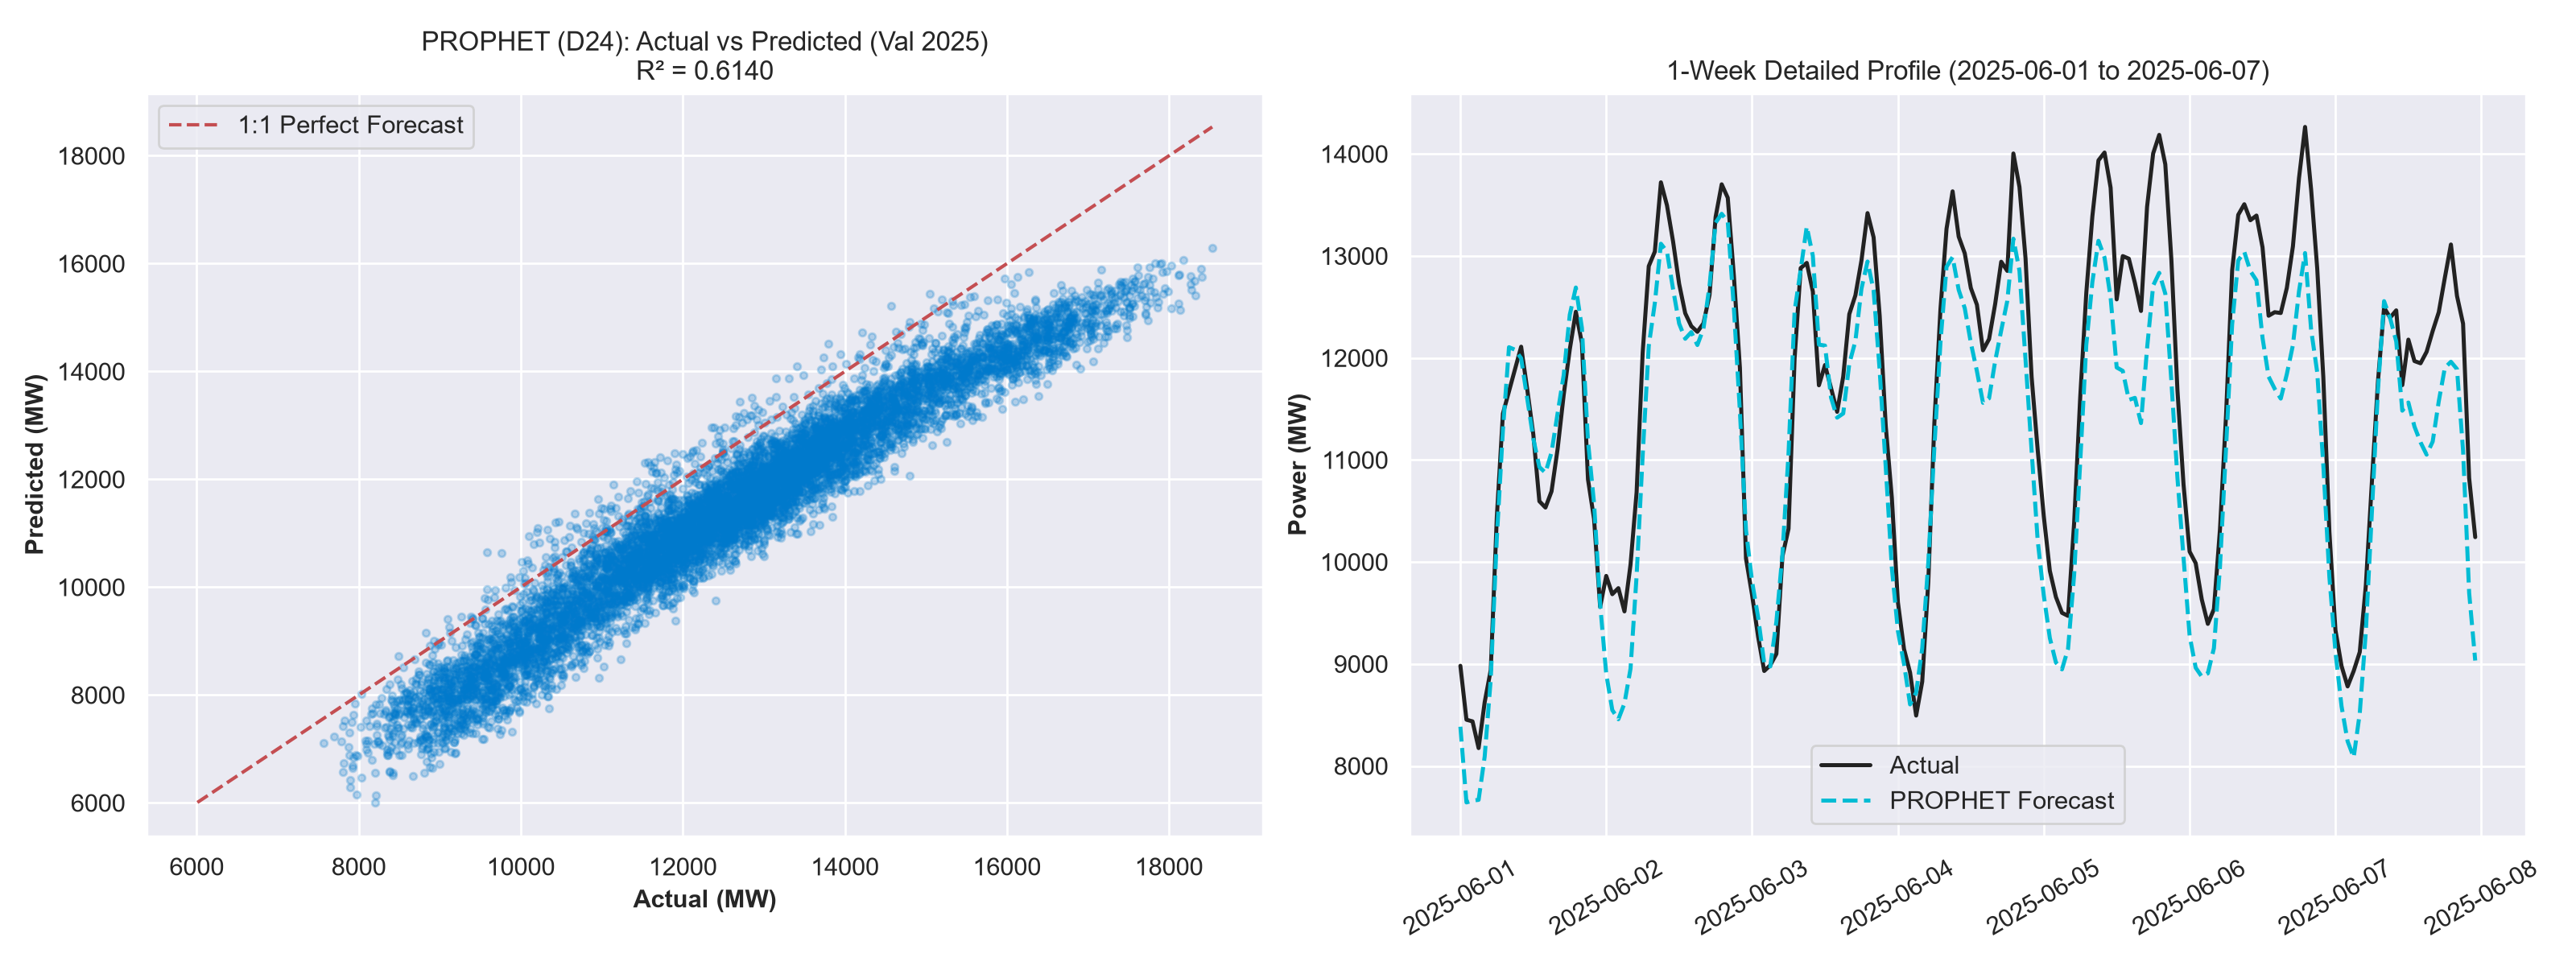

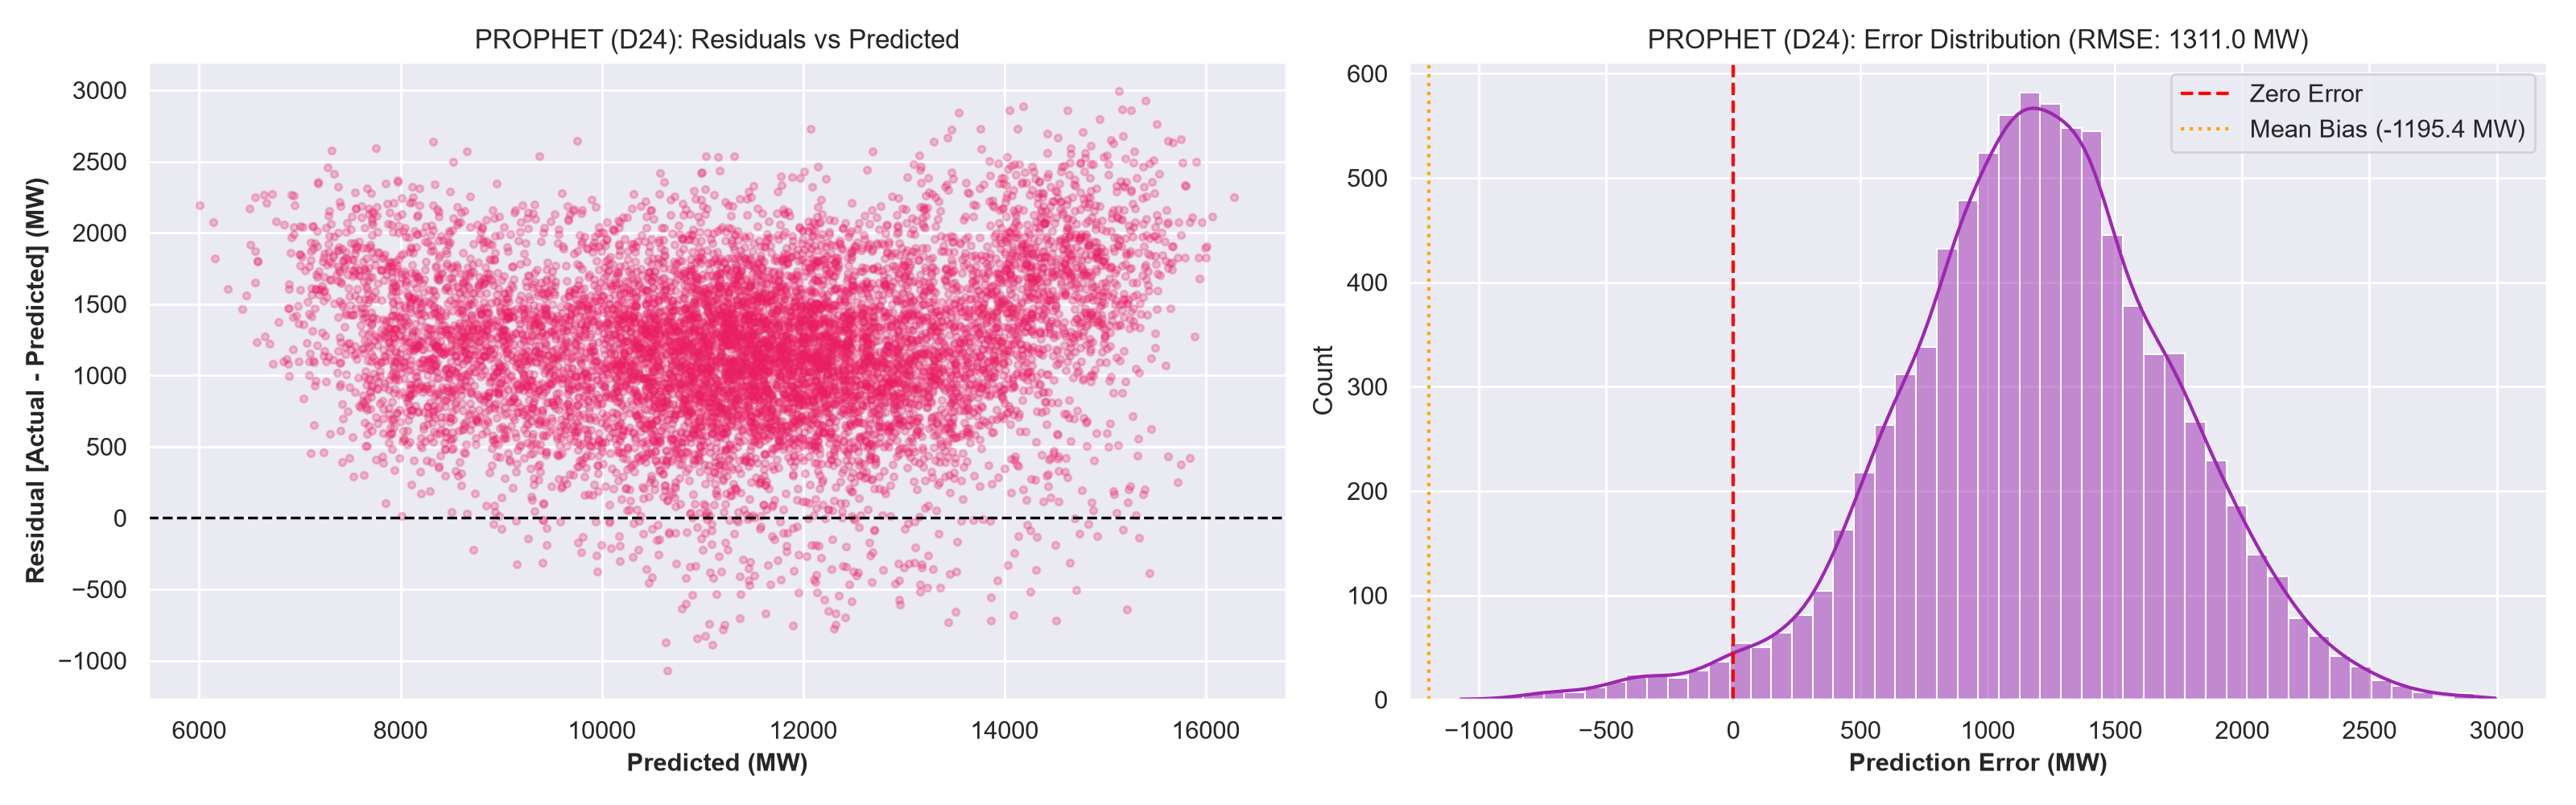


DIAGNOSTIC PLOTS FOR PROBLEM S1


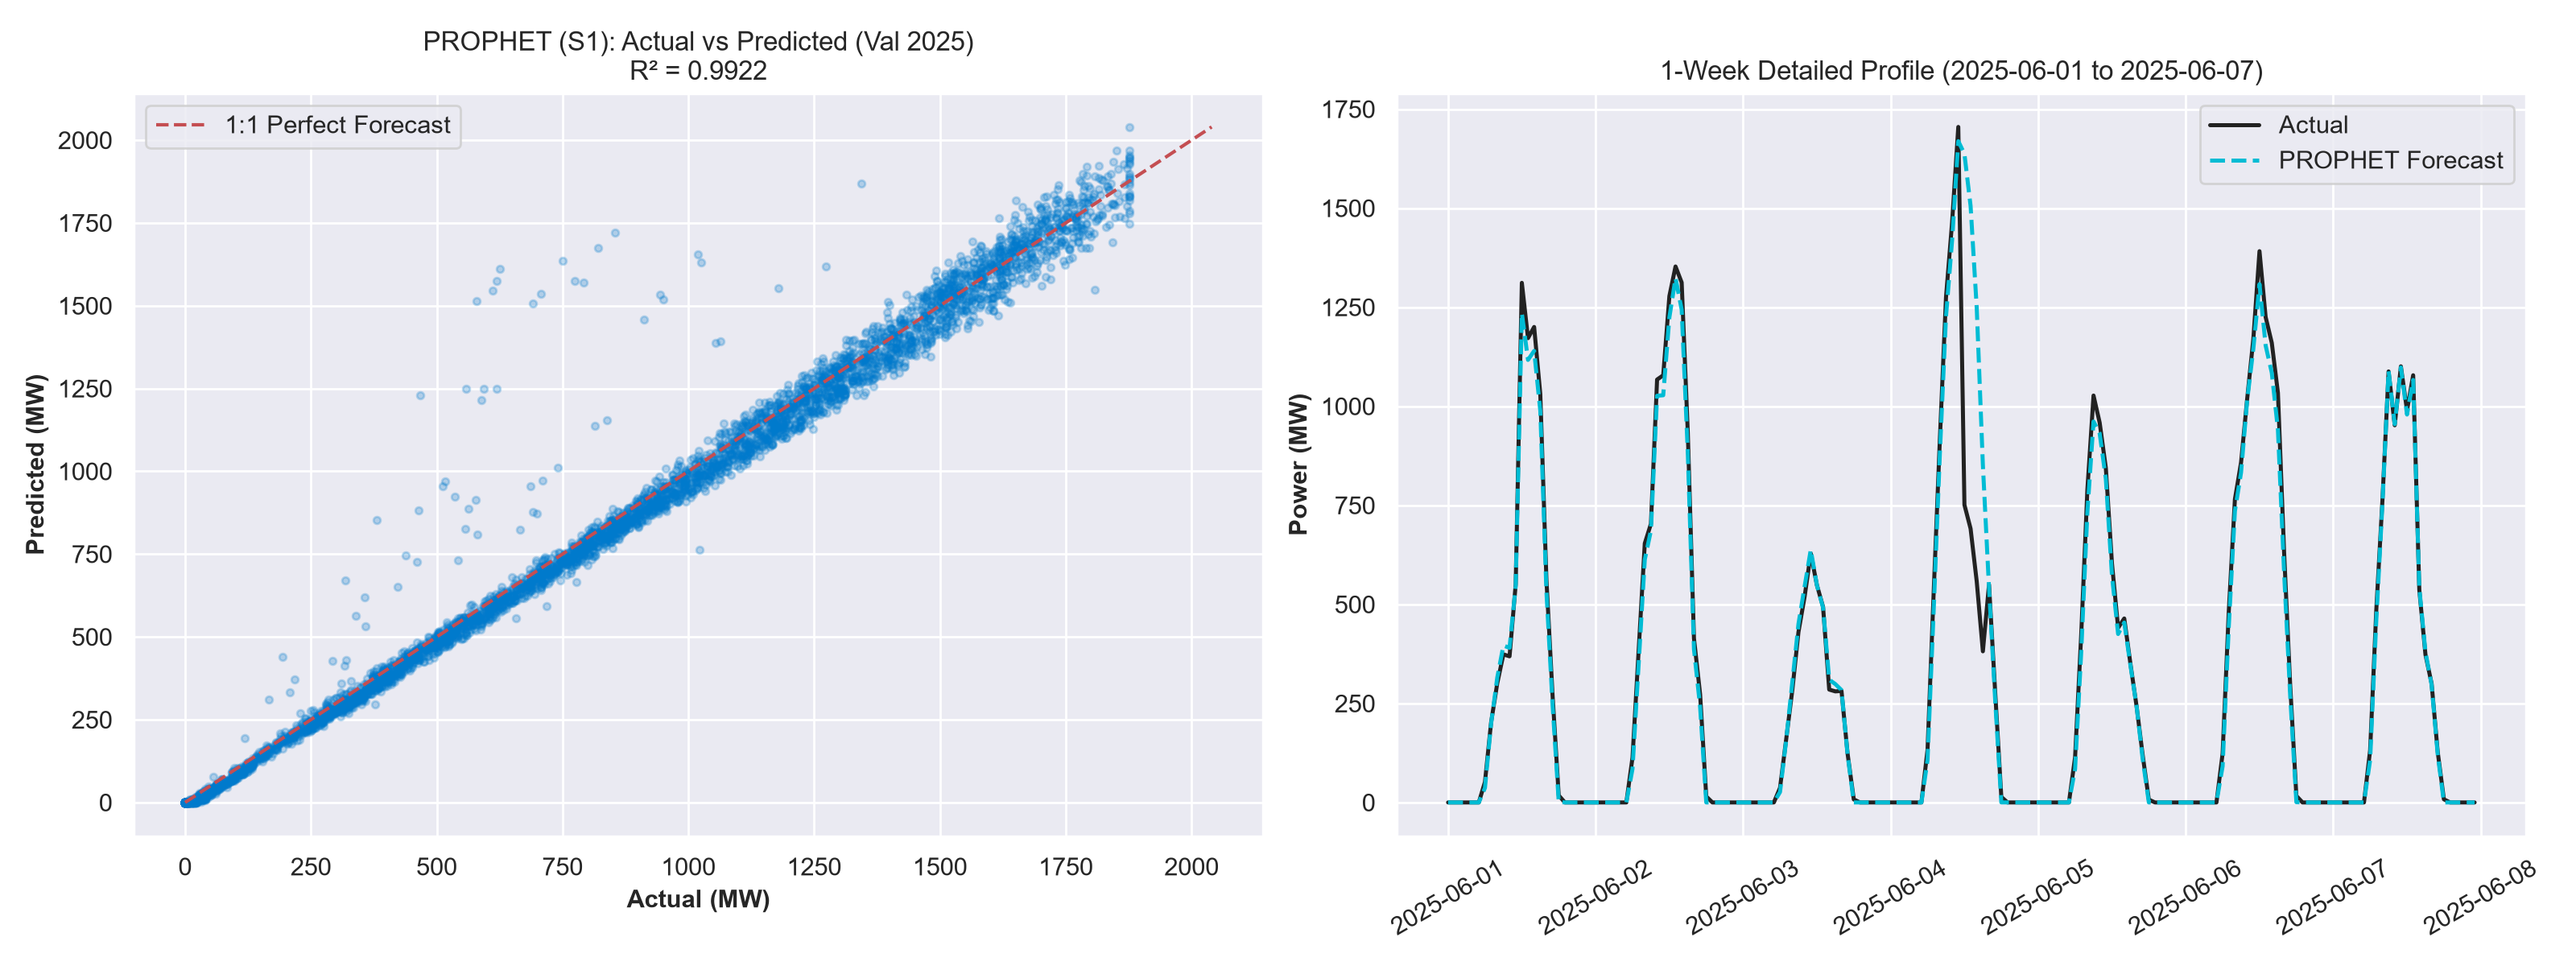

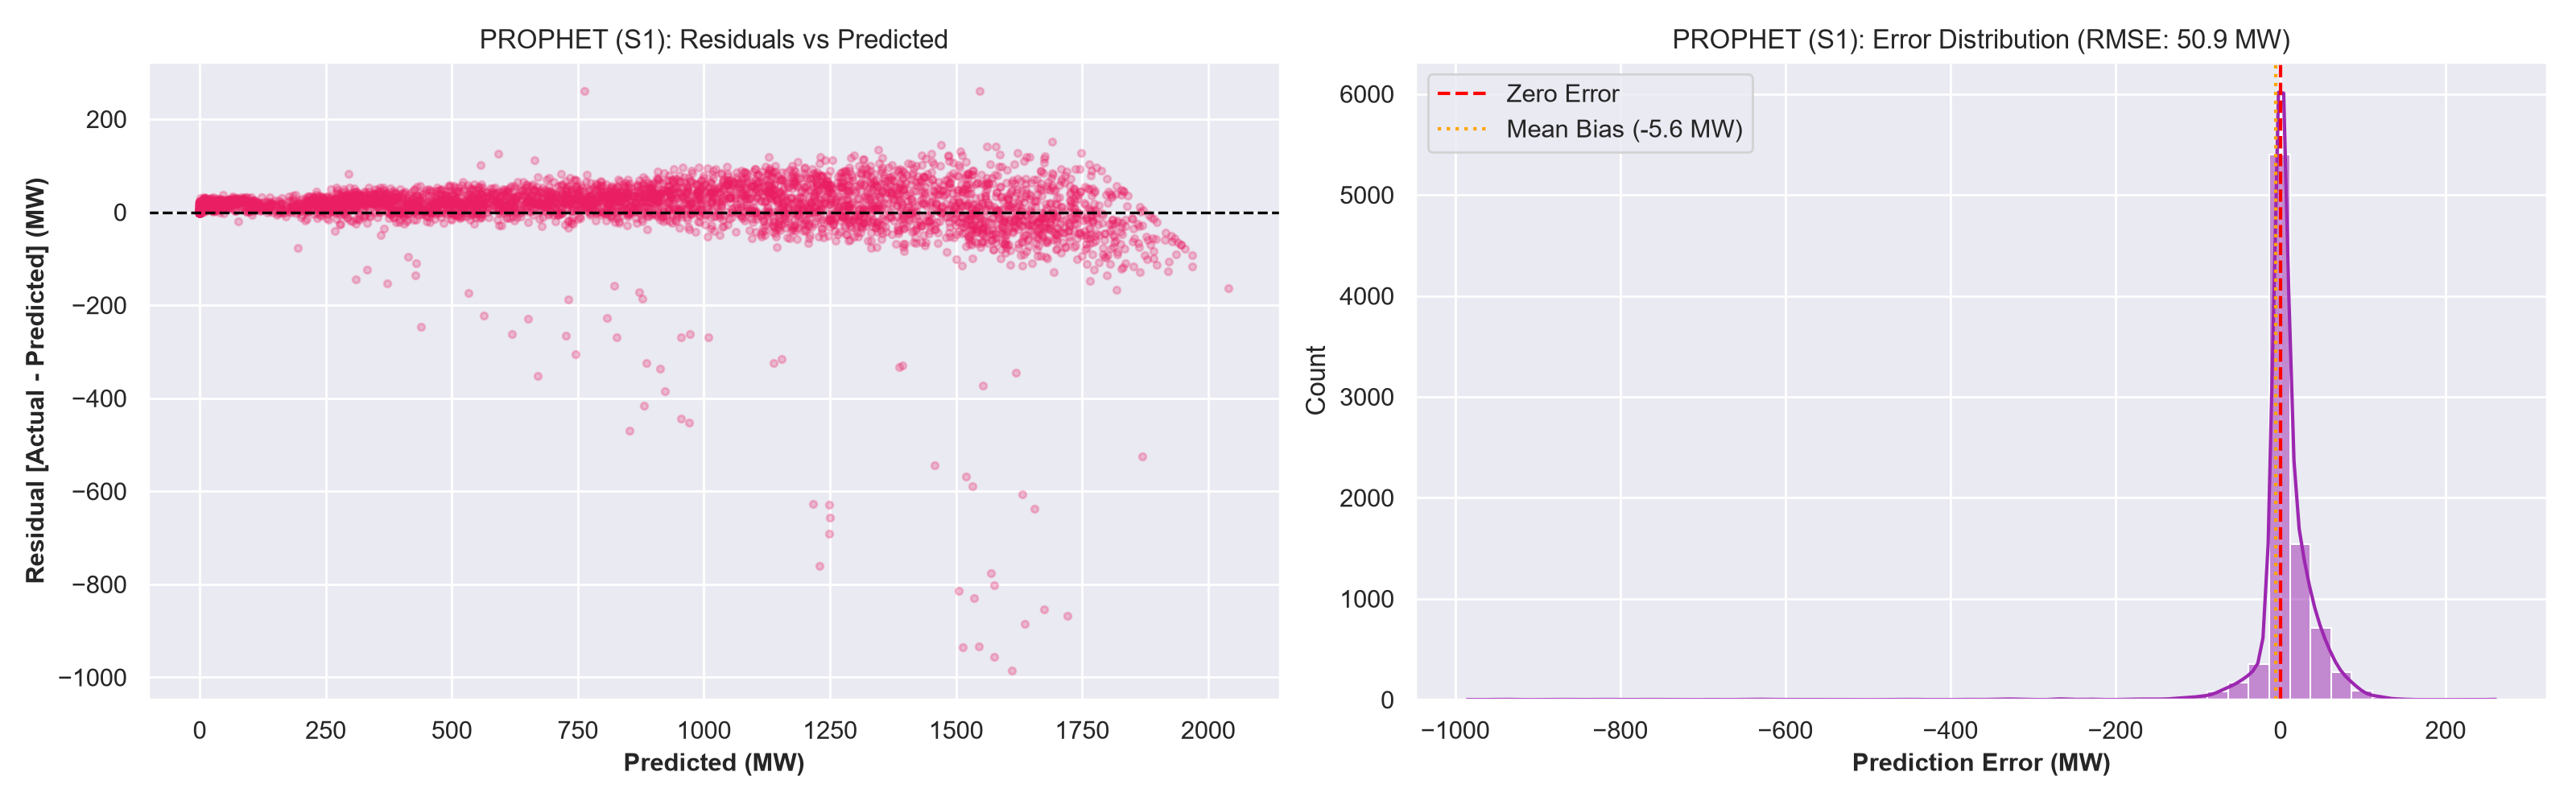


DIAGNOSTIC PLOTS FOR PROBLEM S24


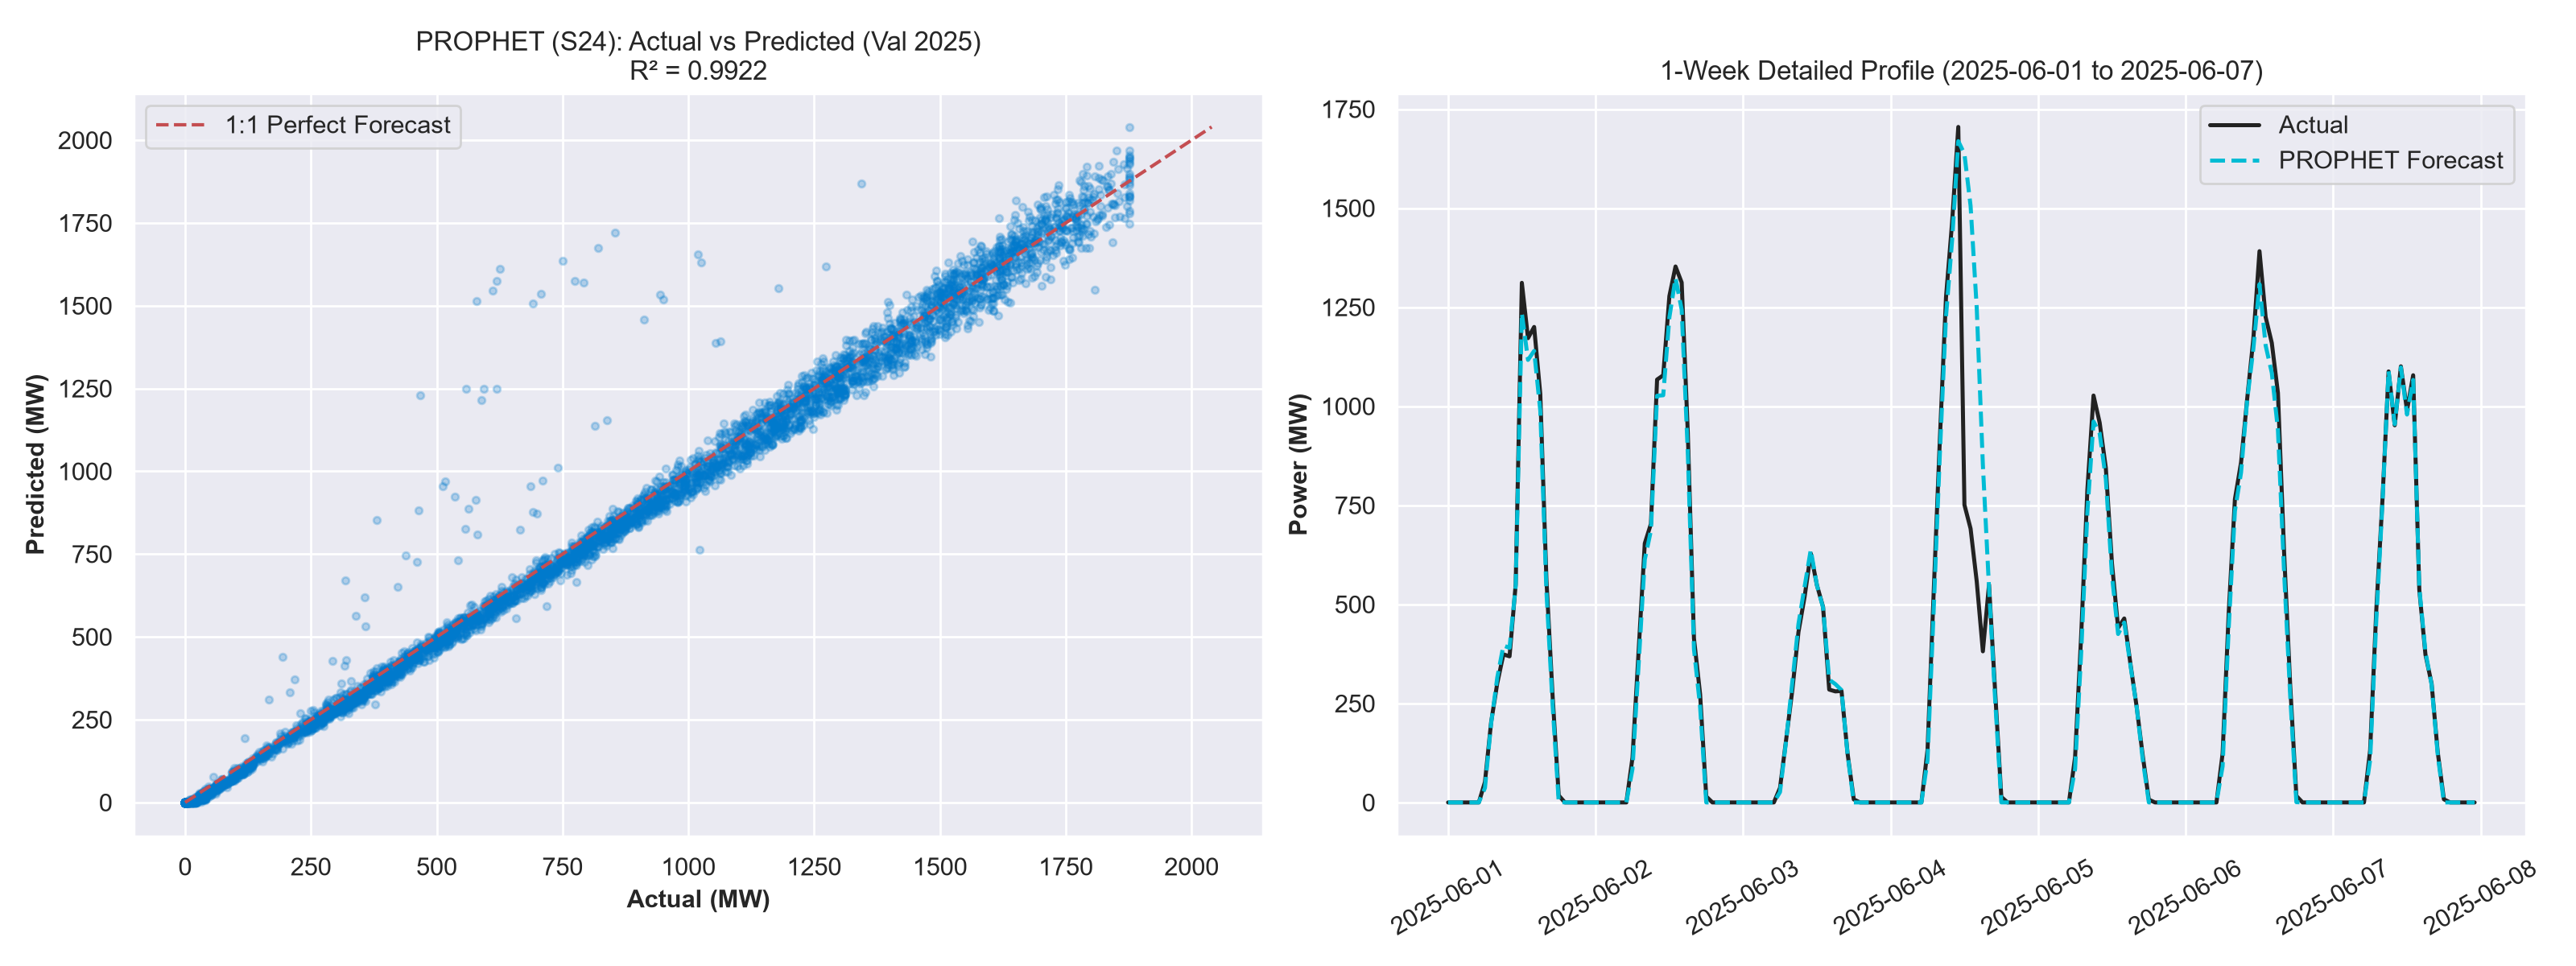

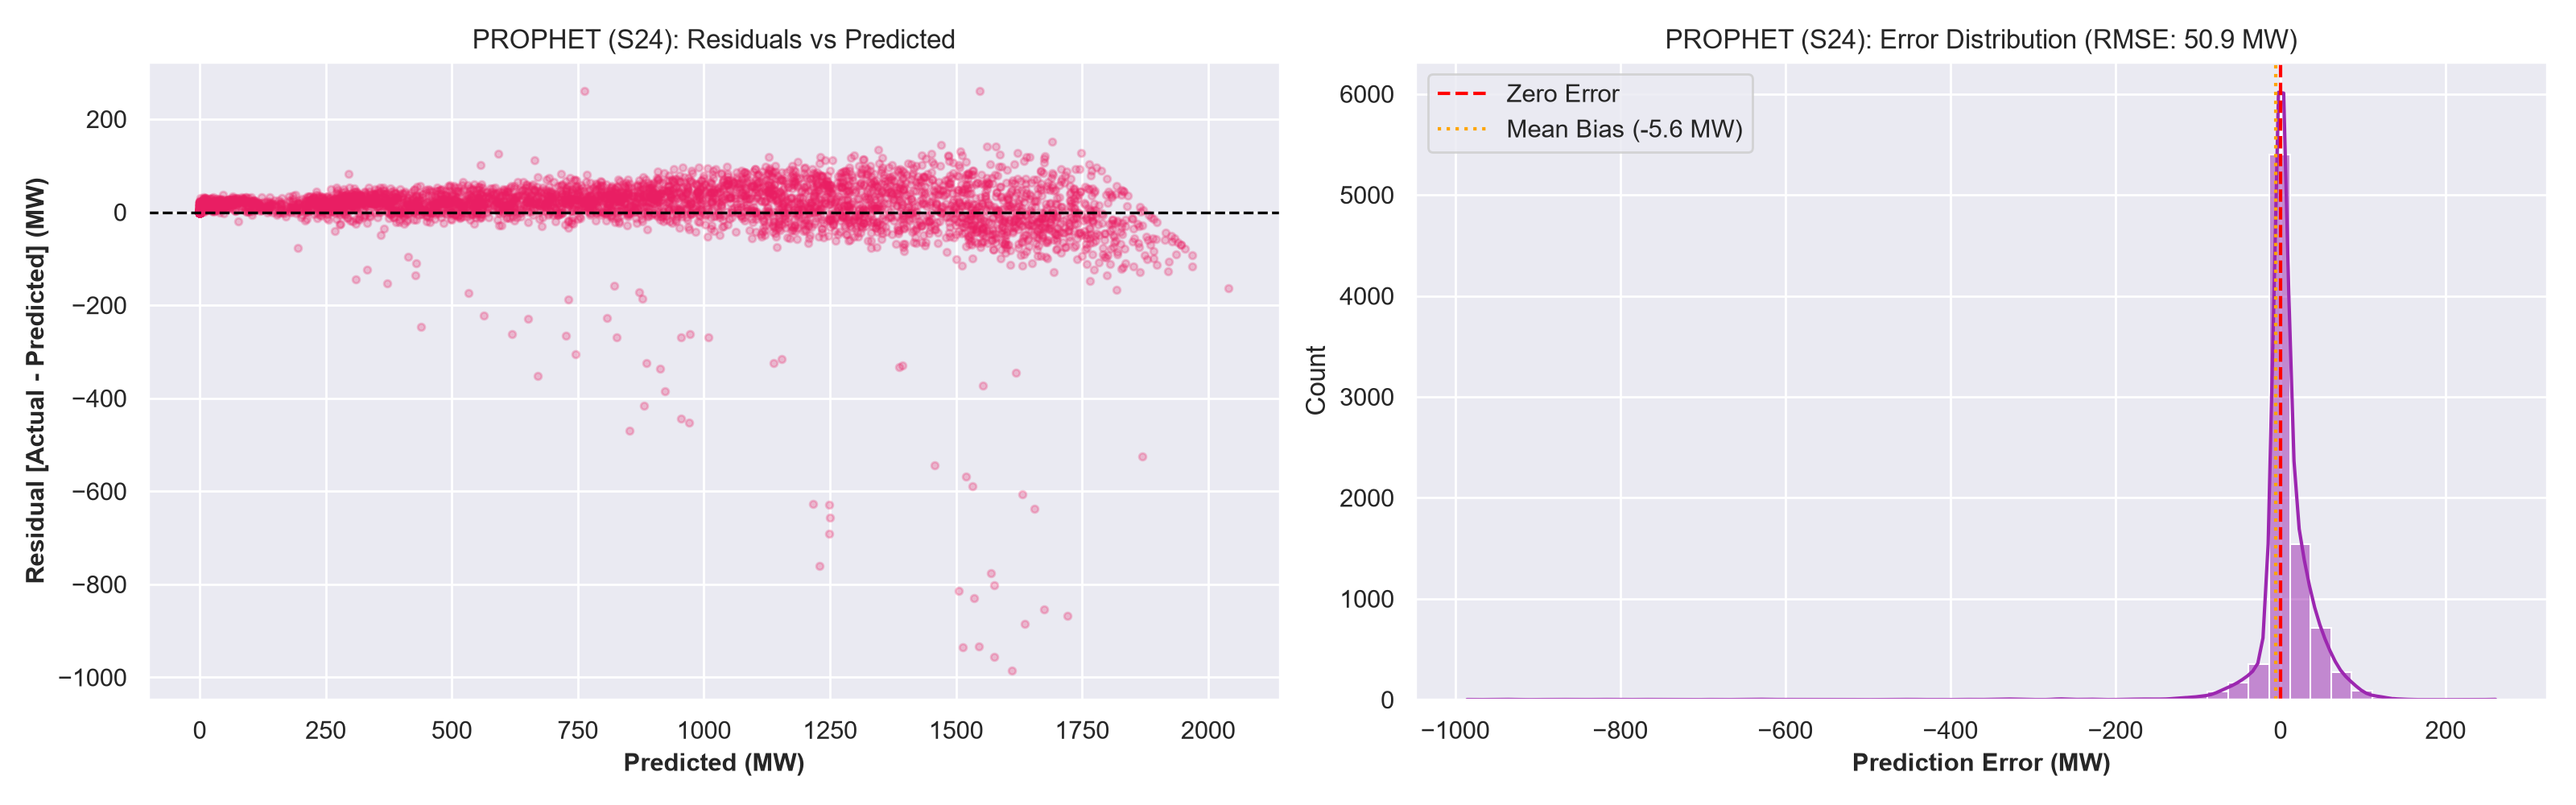

In [4]:
for pid in problems:
    print(f"\n{'='*70}\nDIAGNOSTIC PLOTS FOR PROBLEM {pid}\n{'='*70}")
    fig_actual = config.FIGURES_LINEAR_DIR / f"prophet_{pid}_actual_vs_predicted.png"
    fig_resid = config.FIGURES_LINEAR_DIR / f"prophet_{pid}_residuals_distribution.png"
    if fig_actual.exists():
        display(Image(filename=str(fig_actual)))
    if fig_resid.exists():
        display(Image(filename=str(fig_resid)))
